In [167]:
import math
import matplotlib.pyplot as plt
import numpy as np

In [168]:
def plot_2d_vectors(
    vectors,
    origins=None,
    labels=None,
    colors=None,
    scale=1.0,
    title="2D Force Vectors",
    center_origin=True,
    trajectory=None,
):
    """Plots a collection of 2D vectors with arrows, centered at (0, 0) by default.

    Parameters:
    - vectors: list or (N, 2) array of [vx, vy] components
    - origins: list or (N, 2) array of [x, y] tail positions (defaults to [0,
    0])
    - labels: list of strings for the legend
    - colors: list of color strings
    - scale: multiplier to resize vector lengths visually (default 1.0 = true
    size)
    - center_origin: if True, keeps (0, 0) at the exact center of the plot;
    if False, zooms to fit the vectors and trajectory
    - trajectory: optional list of [x, y] points drawn as a dashed path
    """
    vectors = np.atleast_2d(np.asarray(vectors, dtype=float))
    n = len(vectors)

    if origins is None:
        origins = np.zeros_like(vectors)
    else:
        origins = np.atleast_2d(np.asarray(origins, dtype=float))
        if len(origins) == 1 and n > 1:
            origins = np.repeat(origins, n, axis=0)

    if colors is None:
        colors = plt.cm.tab10(np.linspace(0, 1, max(n, 10)))[:n]

    fig, ax = plt.subplots(figsize=(6, 6))

    # Plot each vector
    for i in range(n):
        vec = vectors[i] * scale
        orig = origins[i]
        lbl = labels[i] if labels and i < len(labels) else f"Vector {i+1}"

        ax.quiver(
            orig[0],
            orig[1],
            vec[0],
            vec[1],
            angles="xy",
            scale_units="xy",
            scale=1,
            color=colors[i],
            width=0.008,
            label=lbl,
        )

    # Calculate bounding points (include trajectory; include (0, 0) only when centering)
    tips = origins + vectors * scale
    pts = [origins, tips]
    if trajectory is not None and len(trajectory) > 0:
        pts.append(np.atleast_2d(np.asarray(trajectory, dtype=float)))
    if center_origin:
        pts.append([[0.0, 0.0]])
    all_pts = np.vstack(pts)

    if trajectory is not None and len(trajectory) > 1:
        traj = np.array(trajectory)
        ax.plot(
            traj[:, 0],
            traj[:, 1],
            "--",
            color="gray",
            alpha=0.7,
            label="Trajectory",
        )

    if center_origin:
        # Find the furthest coordinate from (0, 0) across both X and Y
        max_abs = np.max(np.abs(all_pts)) or 1.0
        limit = max_abs * 1.2  # Add 20% padding
        ax.set_xlim(-limit, limit)
        ax.set_ylim(-limit * 0.1, limit)
    else:
        min_xy = all_pts.min(axis=0)
        max_xy = all_pts.max(axis=0)
        center = (min_xy + max_xy) / 2
        span = np.max(max_xy - min_xy) or 1.0
        half = span * 0.6  # half-span + 10% padding each side, square box
        ax.set_xlim(center[0] - half, center[0] + half)
        ax.set_ylim(center[1] - half, center[1] + half)

    # Draw central axes lines and formatting
    # ax.axvline(0, c="black")
    ax.axhline(0, c="green", lw=2.0)
    ax.set_aspect("equal")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.set_title(title)
    if labels:
        ax.legend(loc="upper left")

    plt.tight_layout()
    plt.show()
    return fig, ax

In [169]:
def plot_missile_state(trajectory, forces, labels, colors, t, dt, v0=None):
    """Four-panel (2x2) view of the simulation.

    1. Trajectory relative to the start point (m), colored by time,
       with the current net-force direction.
    2. Free-body diagram of the forces at true relative scale (N).
    3. Velocity vectors at every step, drawn from a common origin (m/s).
    4. Altitude gain and speed over time.

    Velocities are derived from the trajectory: v[i] = (p[i] - p[i-1]) / dt,
    which is exactly the updated velocity in symplectic Euler. v0 is the
    initial velocity (defaults to [0, 0]).
    """
    traj = np.asarray(trajectory, dtype=float)
    forces = np.atleast_2d(np.asarray(forces, dtype=float))
    rel = traj - traj[0]
    times = np.arange(len(traj)) * dt
    f_mags = np.linalg.norm(forces, axis=1)
    f_max = f_mags.max() or 1.0

    v0 = np.zeros(2) if v0 is None else np.asarray(v0, dtype=float)
    vels = np.vstack([v0, np.diff(traj, axis=0) / dt])
    speeds = np.linalg.norm(vels, axis=1)
    v_max = speeds.max() or 1.0

    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    (ax_traj, ax_fbd), (ax_vel, ax_alt) = axes
    fig.suptitle(f"Missile state at t = {t:.0f} s", fontsize=14, fontweight="bold")
    cmap = plt.cm.viridis
    norm = plt.Normalize(times.min(), max(times.max(), dt))

    # --- 1. Trajectory -------------------------------------------------------
    ax_traj.plot(rel[:, 0], rel[:, 1], "-", color="gray", lw=1.5, alpha=0.5, zorder=1)
    sc = ax_traj.scatter(rel[:, 0], rel[:, 1], c=times, cmap=cmap, norm=norm, s=30, zorder=2)
    fig.colorbar(sc, ax=ax_traj, label="time (s)", shrink=0.85)
    ax_traj.scatter(*rel[0], s=140, facecolors="none", edgecolors="black", lw=2,
                    label="Start", zorder=3)
    ax_traj.scatter(*rel[-1], marker="*", s=300, color="gold", edgecolors="black",
                    label="Current", zorder=4)

    span = max(np.ptp(rel[:, 0]), np.ptp(rel[:, 1]), 1.0)
    center = (rel.min(axis=0) + rel.max(axis=0)) / 2
    half = span * 0.75
    ax_traj.set_xlim(center[0] - half, center[0] + half)
    ax_traj.set_ylim(center[1] - half, center[1] + half)

    # Net force direction at the missile (length = 30% of the view, not to scale)
    net = forces[-1]
    if np.linalg.norm(net) > 0:
        tip = rel[-1] + net / np.linalg.norm(net) * span * 0.3
        ax_traj.annotate("", xy=tip, xytext=rel[-1], zorder=5,
                         arrowprops=dict(arrowstyle="-|>", color=colors[-1], lw=2.5,
                                         mutation_scale=20))
        ax_traj.plot([], [], color=colors[-1], lw=2.5, label=f"{labels[-1]} direction")

    ax_traj.set_aspect("equal")
    ax_traj.set_xlabel("Δx from start (m)")
    ax_traj.set_ylabel("Δy from start (m)")
    ax_traj.set_title("Trajectory")
    ax_traj.grid(True, linestyle="--", alpha=0.4)
    ax_traj.legend(loc="best", fontsize=9)

    # --- 2. Free-body diagram (true relative scale) ---------------------------
    widths = np.linspace(0.035, 0.012, len(forces))  # later (net) arrows thinner, on top
    for i, (f, lbl, c) in enumerate(zip(forces, labels, colors)):
        ax_fbd.quiver(0, 0, f[0], f[1], angles="xy", scale_units="xy", scale=1,
                      color=c, width=widths[i], alpha=0.9, zorder=2 + i, label=lbl)
        ax_fbd.text(f[0] + f_max * 0.06, f[1], f"{lbl}\n{f_mags[i]:,.0f} N",
                    color=c, fontsize=9, fontweight="bold", va="center")
    ax_fbd.scatter(0, 0, s=80, color="black", zorder=10)

    lim = f_max * 1.3
    ax_fbd.set_xlim(-lim, lim)
    ax_fbd.set_ylim(-lim, lim)
    ax_fbd.set_aspect("equal")
    ax_fbd.axhline(0, color="black", lw=0.6)
    ax_fbd.axvline(0, color="black", lw=0.6)
    ax_fbd.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:.0f}k"))
    ax_fbd.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:.0f}k"))
    ax_fbd.set_xlabel("Fx (N)")
    ax_fbd.set_ylabel("Fy (N)")
    ax_fbd.set_title("Free-body diagram (to scale)")
    ax_fbd.grid(True, linestyle="--", alpha=0.4)

    # --- 3. Velocity vectors (to scale, m/s) ----------------------------------
    # Draw longest first so shorter (earlier) vectors stay visible on top.
    order = np.argsort(-speeds)
    for i in order:
        v = vels[i]
        if speeds[i] == 0:
            continue
        is_now = i == len(vels) - 1
        ax_vel.quiver(0, 0, v[0], v[1], angles="xy", scale_units="xy", scale=1,
                      color="darkorange" if is_now else cmap(norm(times[i])),
                      width=0.018 if is_now else 0.010,
                      alpha=1.0 if is_now else 0.8, zorder=3 if is_now else 2)
    ax_vel.scatter(vels[:, 0], vels[:, 1], c=times, cmap=cmap, norm=norm,
                   s=25, edgecolors="black", lw=0.5, zorder=4)
    ax_vel.text(vels[-1, 0] + v_max * 0.06, vels[-1, 1],
                f"now: {speeds[-1]:,.1f} m/s", color="darkorange",
                fontsize=10, fontweight="bold", va="center")
    ax_vel.scatter(0, 0, s=80, color="black", zorder=10)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    fig.colorbar(sm, ax=ax_vel, label="time (s)", shrink=0.85)

    vlim = v_max * 1.3
    ax_vel.set_xlim(-vlim, vlim)
    ax_vel.set_ylim(-vlim, vlim)
    ax_vel.set_aspect("equal")
    ax_vel.axhline(0, color="black", lw=0.6)
    ax_vel.axvline(0, color="black", lw=0.6)
    ax_vel.set_xlabel("Vx (m/s)")
    ax_vel.set_ylabel("Vy (m/s)")
    ax_vel.set_title("Velocity vectors per step (to scale)")
    ax_vel.grid(True, linestyle="--", alpha=0.4)

    # --- 4. Altitude gain & speed over time -----------------------------------
    r = np.linalg.norm(traj, axis=1)
    ax_alt.plot(times, r - r[0], "o-", color="tab:blue", ms=4, label="Altitude gain")
    ax_alt.set_xlabel("time (s)")
    ax_alt.set_ylabel("Altitude gain (m)", color="tab:blue")
    ax_alt.tick_params(axis="y", labelcolor="tab:blue")
    ax_alt.grid(True, linestyle="--", alpha=0.4)

    ax_spd = ax_alt.twinx()
    ax_spd.plot(times, speeds, "s--", color="darkorange", ms=4, label="Speed")
    ax_spd.set_ylabel("Speed (m/s)", color="darkorange")
    ax_spd.tick_params(axis="y", labelcolor="darkorange")
    ax_alt.set_title("Altitude & speed")

    plt.tight_layout()
    plt.show()
    return fig

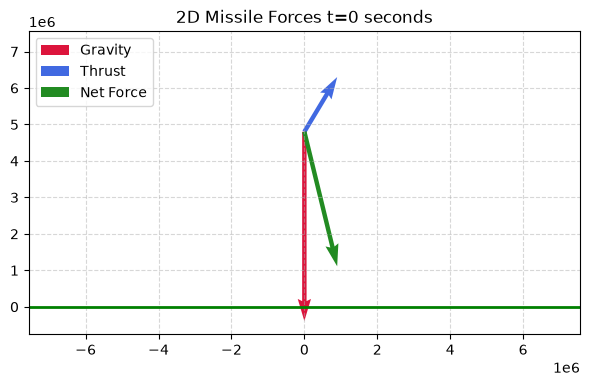

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': '2D Missile Forces t=0 seconds'}>)

In [170]:
G = 6.67430e-11
M_earth = 5.972e24
m_missile = 1000.0

pos_missile = np.array([0, 4.8e6])
r_mag = np.linalg.norm(pos_missile)

# Force vectors (in Newtons)
f_gravity = -G * M_earth * m_missile * pos_missile / (r_mag**3)
f_thrust = np.array([3000.0, 5000.0])
f_net = f_gravity + f_thrust

# Scale Newtons (~10^3) to match spatial coordinates (~10^6 meters)
plot_2d_vectors(
    vectors=[f_gravity, f_thrust, f_net],
    origins=pos_missile,
    labels=["Gravity", "Thrust", "Net Force"],
    colors=["crimson", "royalblue", "forestgreen"],
    scale=300,
    title="2D Missile Forces t=0 seconds",
)

In [224]:
G = 6.67430e-11
M_earth = 5.972e24
m_missile = 1000.0

pos_missile = np.array([0.0, 4.8e6])  # Initial position (m)
vel_missile = np.array([0.0, 0.0])  # Initial orbital velocity (m/s)

# Weight at this altitude: G*M*m/r^2 ≈ 17,300 N. Thrust must exceed it to climb.
f_thrust = np.array([0, 30000.0])  # Constant thrust vector (N) -> net ≈ +12,700 N up

# --- Discrete Time Settings ---
dt = 1.0  # Time step (seconds)
step = 1

trajectory = [pos_missile.copy()]

Thrust angle estimated: 90.0 degrees
Thrust angle estimated: 90.0 degrees
Thrust angle estimated: 90.0 degrees
Thrust angle estimated: 90.0 degrees
Thrust angle estimated: 90.0 degrees
Thrust angle estimated: 89.0 degrees
Thrust angle estimated: 88.0 degrees
Thrust angle estimated: 87.0 degrees
Thrust angle estimated: 86.0 degrees
Thrust angle estimated: 84.99999999999999 degrees
Thrust angle estimated: 83.99999999999999 degrees
Thrust angle estimated: 82.99999999999999 degrees
Thrust angle estimated: 81.99999999999999 degrees
Thrust angle estimated: 80.99999999999999 degrees
Thrust angle estimated: 79.99999999999999 degrees
Thrust angle estimated: 78.99999999999999 degrees
Thrust angle estimated: 77.99999999999999 degrees
Thrust angle estimated: 76.99999999999999 degrees
Thrust angle estimated: 75.99999999999999 degrees
Thrust angle estimated: 74.99999999999997 degrees
Thrust angle estimated: 73.99999999999997 degrees
Thrust angle estimated: 72.99999999999997 degrees
Thrust angle esti

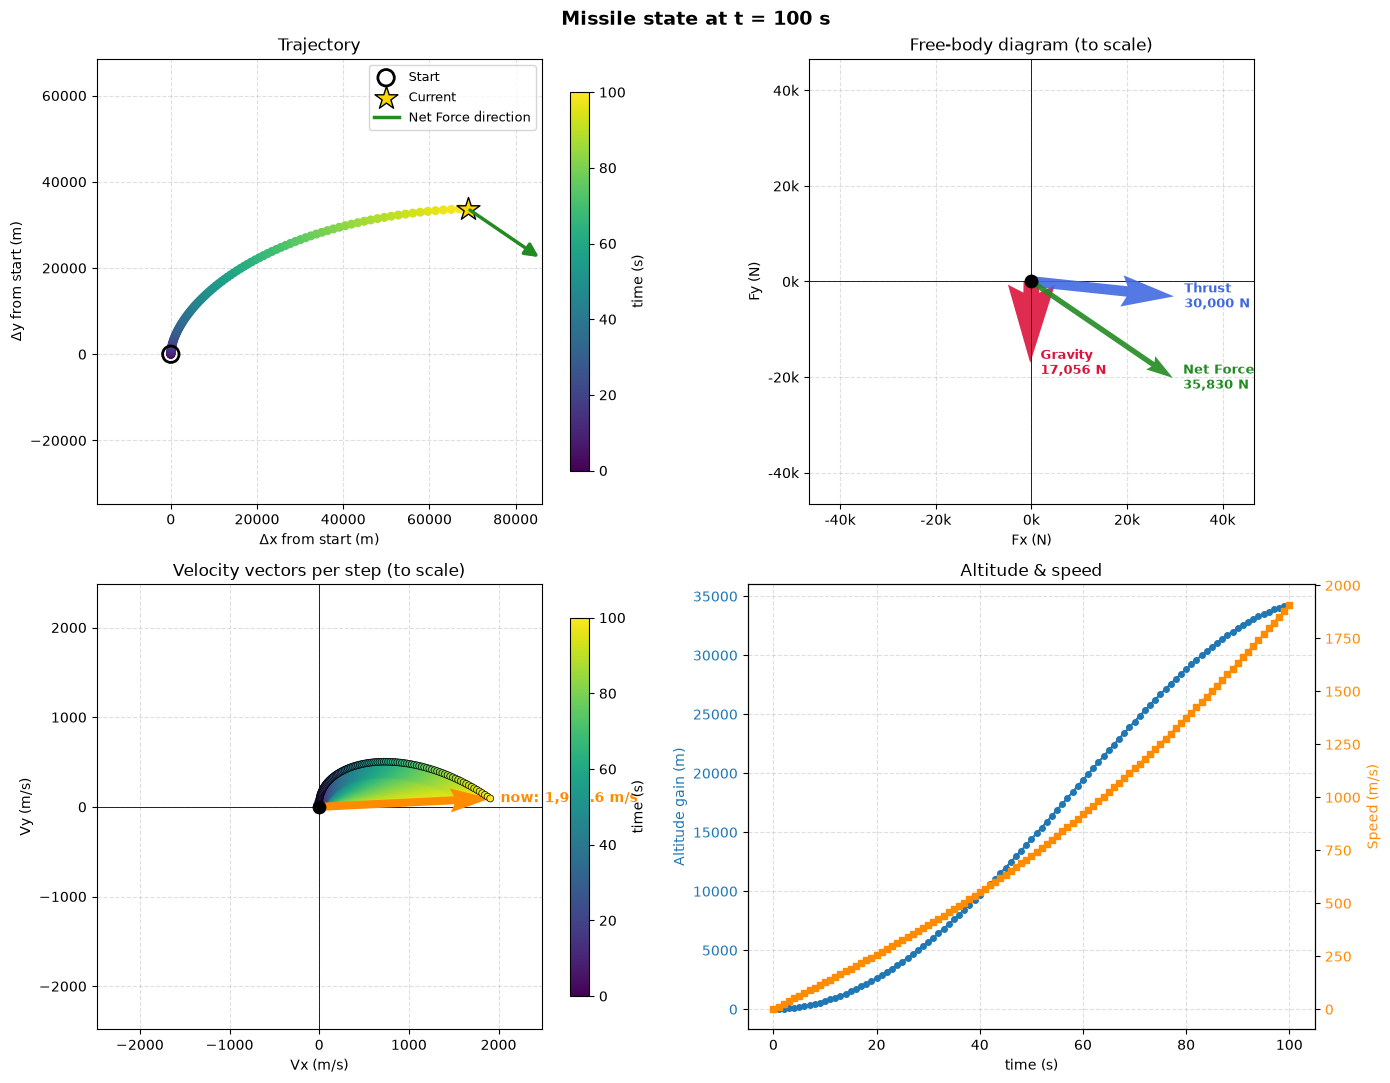

In [225]:


for _ in range(100):  # Simulate 100 steps
    t = step * dt
    step += 1

    # 1. Compute forces at current position
    r_mag = np.linalg.norm(pos_missile)
    f_gravity = -G * M_earth * m_missile * pos_missile / (r_mag**3)

    f_thrust_angle = np.arctan2(f_thrust[1], f_thrust[0])
    print(f"Thrust angle estimated: {np.degrees(f_thrust_angle)} degrees")

    if step > 5:
        f_thrust_angle -= np.radians(1)  # Example: decrease thrust angle by 5 degrees
        f_thrust = np.array([np.cos(f_thrust_angle), np.sin(f_thrust_angle)]) * np.linalg.norm(f_thrust)

    f_net = f_gravity + f_thrust

    # 3. Discrete Kinematics Update (Symplectic Euler)
    accel = f_net / m_missile
    vel_missile = vel_missile + accel * dt
    pos_missile = pos_missile + vel_missile * dt
    trajectory.append(pos_missile.copy())


# trailing ";" stops Jupyter from displaying the returned Figure a second time
plot_missile_state(
    trajectory=trajectory,
    forces=[f_gravity, f_thrust, f_net],  # net force last
    labels=["Gravity", "Thrust", "Net Force"],
    colors=["crimson", "royalblue", "forestgreen"],
    t=t,
    dt=dt,
);